# Agente de Blackjack con Q-learning

**Aprendizaje por refuerzo**

En aprendizaje por refuerzo nadie le enseña al programa cómo se juega. El programa prueba,
pierde, gana, y poco a poco se va quedando con lo que le funcionó. Aquí ese programa —el
**agente**— aprende a jugar blackjack.

Lo bonito de haber elegido blackjack es que el blackjack ya tiene una respuesta correcta
conocida. Existe una tabla, la **estrategia básica**, que dice cuál es la mejor jugada para cada
combinación de tu mano contra la carta que enseña el dealer. No es una opinión ni un truco de
jugador: es el resultado de calcular las probabilidades de todas las formas en que puede
terminar la mano. En los casinos hasta la venden impresa en tarjetas. Entonces podemos dejar al
agente aprender solo y después **comparar su tabla contra la respuesta correcta**, casilla por
casilla, y medir qué tan cerca quedó.

| | |
|---|---|
| Ambiente | `Blackjack-v1` de gymnasium |
| Lo que ve el agente | su total, la carta destapada del dealer, y si tiene un as que puede valer 11 |
| Lo que puede hacer | plantarse (0) o pedir carta (1) |
| Lo que recibe | +1 si gana la mano, 0 si empata, −1 si pierde |
| Cómo aprende | Q-learning tabular con ε-greedy |

---

## 1. El ambiente


El primero es el **espacio de observaciones** (`observation_space`): la lista de todo lo que el
agente alcanza a ver. Aquí es una terna de tres números enteros:

1. **Su total.** La suma de sus cartas.
2. **La carta destapada del dealer.** Un número del 1 al 10, donde el 1 es el as.
3. **Si tiene un as aprovechable.** Vale 1 cuando el agente trae un as que puede contar como 11
   sin pasarse de 21, y 0 si no. Importa muchísimo, porque con ese as no puede perder al pedir:
   si se pasa, el as simplemente baja a valer 1.

Cuando se imprime sale escrito como `Tuple(Discrete(32), Discrete(11), Discrete(2))`. `Discrete(n)`
quiere decir "un número entero entre 0 y n−1", así que eso se lee como: el primer número va de 0
a 31, el segundo de 0 a 10 y el tercero es 0 o 1. Los rangos van holgados a propósito; en la
práctica el total nunca baja de 4 ni pasa de 21.

El segundo es el **espacio de acciones** (`action_space`), que es todo lo que el agente puede
hacer. Aquí son dos opciones nada más: `0` plantarse y `1` pedir otra carta.


In [13]:
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
import functools, time, os
from matplotlib.patches import FancyBboxPatch, Rectangle, Circle, Arc
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.backends.backend_agg import FigureCanvasAgg

env = gym.make("Blackjack-v1")
print("observation_space:", env.observation_space)
print("  -> (suma del jugador, carta visible del dealer, as usable)")
print("action_space     :", env.action_space, "-> 0 = plantarse, 1 = pedir")

obs, info = env.reset(seed=7)
print("\nobservación:", obs)
print("cartas reales -> jugador:", env.unwrapped.player, "| dealer:", env.unwrapped.dealer)
print("recompensa: +1 gana, 0 empata, -1 pierde (una sola al final de la mano)")
print("variante sab =", env.unwrapped.sab, "(la de Sutton & Barto, baraja infinita)")

observation_space: Tuple(Discrete(32), Discrete(11), Discrete(2))
  -> (suma del jugador, carta visible del dealer, as usable)
action_space     : Discrete(2) -> 0 = plantarse, 1 = pedir

observación: (19, 10, 0)
cartas reales -> jugador: [9, 10] | dealer: [10, 9]
recompensa: +1 gana, 0 empata, -1 pierde (una sola al final de la mano)
variante sab = True (la de Sutton & Barto, baraja infinita)


### Qué dice esa primera observación

`env.reset()` reparte una mano nueva: dos cartas al agente y dos al dealer, una de ellas tapada.
Lo que devuelve es la **primera observación**, o sea la foto de la situación justo antes de la
primera decisión. Con la semilla 7 salió `(19, 10, 0)`, que se lee así: el agente tiene 19, el
dealer enseña un 10, y el agente no tiene un as aprovechable.

Abajo se imprimen también las cartas de verdad, que salen de `env.unwrapped` y que el agente
nunca ve. Sirven para dibujar la mesa más adelante: el jugador tenía `[9, 10]` y el dealer
`[10, 9]`, donde ese segundo 9 es la carta tapada.

Hay un detalle del ambiente que conviene dejar claro porque cambia los cálculos. `Blackjack-v1`
tiene dos variantes y la que viene por defecto es **sab**, que son las iniciales de Sutton y
Barto, los autores del libro clásico de aprendizaje por refuerzo. Esa variante sigue las reglas
tal como el libro las plantea: un blackjack natural (as más figura en las dos primeras cartas)
paga +1 igual que cualquier otra victoria, en lugar del 1.5 que pagan los casinos, y si los dos
tienen blackjack es empate. La otra diferencia importante, que aplica en las dos variantes, es
que la baraja es **infinita**: cada carta se saca al azar y se devuelve, así que no se gastan.
Por eso aquí contar cartas no serviría de nada, y por eso también la respuesta exacta se puede
calcular limpiamente en la siguiente celda.

## 2. La respuesta exacta, calculada a mano

Para poder decir que el agente aprendió *bien*, primero hay que saber cuál era la respuesta
correcta. En blackjack se puede calcular, y aquí la calculamos nosotros en vez de copiarla.

La idea es sencilla de contar aunque el código se vea denso. Como la baraja es infinita, sabemos
exactamente con qué probabilidad sale cada carta: 1 entre 13 para cada figura, salvo el 10 que
sale 4 de cada 13 porque el 10, la J, la Q y la K valen lo mismo. El dealer no decide nada, sigue
una regla fija: pide mientras tenga menos de 17 y se planta ahí. Con esas dos cosas se puede
calcular, para cada carta que enseñe el dealer, la probabilidad de que termine en 17, en 18, en
19, en 20, en 21 o pasado de 21.

Teniendo eso, en cada situación se comparan dos números: cuánto ganas en promedio si te plantas
ahora, y cuánto ganas en promedio si pides (tomando en cuenta que después de pedir vuelves a
enfrentar la misma decisión, que es la parte recursiva). Se elige el mayor de los dos y listo:
esa es la jugada óptima para esa casilla. El resultado es `OPTIMA`.

También guardamos `BRECHA`, que es la diferencia entre esos dos números. Sirve para saber **cuánto
cuesta equivocarse** en cada casilla: hay situaciones donde pedir y plantarse valen casi lo mismo
y da igual qué hagas, y otras donde elegir mal te cuesta caro. Al final lo vamos a usar para
mostrar que los pocos errores del agente cayeron justo en las casillas donde casi da lo mismo.

Las cinco líneas de `assert` comprueban contra jugadas que cualquier manual de blackjack confirma,
por ejemplo que con 16 contra un 10 del dealer hay que pedir aunque dé miedo.

In [14]:
PROB = {c: (4 / 13 if c == 10 else 1 / 13) for c in range(1, 11)}


def _pedir(total, usable, carta):
    """Suma una carta aplicando la regla del as (vale 11 si no pasa de 21)."""
    if carta == 1 and total + 11 <= 21:
        total, usable = total + 11, True
    else:
        total += carta
    if total > 21 and usable:
        total, usable = total - 10, False
    return total, usable


@functools.lru_cache(None)
def dist_dealer(total, usable):
    """Probabilidad de cada total final del dealer (se planta en 17)."""
    if total >= 17:
        return {total: 1.0}
    salida = {}
    for carta, p in PROB.items():
        t, u = _pedir(total, usable, carta)
        if t > 21:
            salida["bust"] = salida.get("bust", 0.0) + p
        else:
            for k, q in dist_dealer(t, u).items():
                salida[k] = salida.get(k, 0.0) + p * q
    return salida


def dist_desde_carta(c):
    return dist_dealer(11, True) if c == 1 else dist_dealer(c, False)


@functools.lru_cache(None)
def ev_plantarse(suma, carta_dealer):
    ev = 0.0
    for final, p in dist_desde_carta(carta_dealer).items():
        if final == "bust" or final < suma:
            ev += p
        elif final > suma:
            ev -= p
    return ev


@functools.lru_cache(None)
def ev_pedir(suma, carta_dealer, usable):
    ev = 0.0
    for carta, p in PROB.items():
        t, u = _pedir(suma, usable, carta)
        ev += p * (-1.0 if t > 21 else max(ev_plantarse(t, carta_dealer), ev_pedir(t, carta_dealer, u)))
    return ev


OPTIMA = np.zeros((32, 11, 2), dtype=int)     # 1 = pedir, 0 = plantarse
BRECHA = np.zeros((32, 11, 2))                # |EV_pedir - EV_plantarse|: cuanto cuesta equivocarse
for u in (0, 1):
    for suma in range(4, 22):
        for dc in range(1, 11):
            h, s = ev_pedir(suma, dc, bool(u)), ev_plantarse(suma, dc)
            OPTIMA[suma, dc, u] = int(h > s)
            BRECHA[suma, dc, u] = abs(h - s)

assert OPTIMA[16, 10, 0] == 1, "16 contra 10 debe pedir"
assert OPTIMA[13, 2, 0] == 0, "13 contra 2 debe plantarse"
assert OPTIMA[18, 9, 1] == 1, "18 suave contra 9 debe pedir"
assert OPTIMA[18, 8, 1] == 0, "18 suave contra 8 debe plantarse"
assert OPTIMA[12, 3, 0] == 1, "12 contra 3 debe pedir"
print("oráculo exacto listo y verificado contra 5 casillas conocidas")
print("ejemplo: 16 vs 10 -> EV pedir %.4f | EV plantarse %.4f"
      % (ev_pedir(16, 10, False), ev_plantarse(16, 10)))

oráculo exacto listo y verificado contra 5 casillas conocidas
ejemplo: 16 vs 10 -> EV pedir -0.5693 | EV plantarse -0.5758


## 3. Contra qué lo vamos a comparar

Una **política** es simplemente la regla que usa un jugador para decidir qué hacer en cada
situación. "Si tengo menos de 17, pido" es una política. La tabla que el agente va a aprender
también es una política.

Aquí medimos cuatro políticas que están escritas a mano y **no aprenden nada**: son reglas fijas,
no tienen tabla, no se actualizan, no cambian nunca por más que jueguen. Están para ponerle
marcas a la regla con la que después vamos a medir al agente.

- **Óptima exacta**: juega siempre lo que dice el cálculo de la celda anterior. Es el techo, lo
  mejor que se puede hacer con estas reglas.
- **Aleatoria**: lanza una moneda en cada decisión. Es el piso.
- **Siempre plantarse**: nunca pide carta. Nunca se pasa de 21, pero se queda corto casi siempre.
- **Imitar al dealer**: pide mientras tenga menos de 17, igual que el repartidor. Es lo que juega
  mucha gente por intuición.

Lo que se mide de cada una es el **EV**, de *expected value*, el **valor esperado**: cuánto gana o
pierde en promedio por mano, medido en apuestas. Un EV de −0.0421 significa que por cada peso
apostado se pierden 4.21 centavos *en promedio y a la larga*; en una mano suelta se gana o se
pierde el peso completo. Todas las políticas dan negativo, incluso la perfecta, porque la casa
tiene ventaja: el jugador juega primero y si se pasa de 21 pierde de inmediato, aunque el dealer
también se fuera a pasar después.

Esta celda tarda alrededor de un minuto porque juega 300 mil manos con cada política.

In [15]:
def evaluar(politica, n=300_000, semilla=0):
    """Ganancia promedio por mano de una política dada."""
    e = gym.make("Blackjack-v1")
    e.reset(seed=semilla)
    e.action_space.seed(semilla)
    rng = np.random.default_rng(semilla)
    total = ganadas = empates = 0.0
    for _ in range(n):
        s, _ = e.reset()
        fin, r = False, 0.0
        while not fin:
            s, r, term, trunc, _ = e.step(politica(s, rng))
            fin = term or trunc
        total += r
        ganadas += r > 0
        empates += r == 0
    return total / n, 100 * ganadas / n, 100 * empates / n


BASES = {}
for nombre, pol in [
    ("óptima exacta", lambda s, rng: int(OPTIMA[s[0], s[1], s[2]]) if s[0] >= 4 else 1),
    ("aleatoria", lambda s, rng: int(rng.integers(2))),
    ("siempre plantarse", lambda s, rng: 0),
    ("imitar dealer", lambda s, rng: int(s[0] < 17)),
]:
    BASES[nombre] = evaluar(pol)
    print(f"{nombre:20s} EV {BASES[nombre][0]:+.4f} | gana {BASES[nombre][1]:.1f}% | empata {BASES[nombre][2]:.1f}%")

óptima exacta        EV -0.0421 | gana 43.4% | empata 9.1%
aleatoria            EV -0.3915 | gana 28.4% | empata 4.1%
siempre plantarse    EV -0.1809 | gana 38.5% | empata 4.9%
imitar dealer        EV -0.0746 | gana 41.2% | empata 10.2%


## 4. El ambiente gráfico: colores y piezas

A partir de aquí se construye la mesa de blackjack que se va a ver en el video. El estilo es
*Casino de medianoche*: fieltro verde con un degradado al centro, detalles dorados y cartas color
crema con sombra.

Esta celda define la paleta de colores y las piezas sueltas con las que se dibuja todo: una
carta, una ficha y el fondo de la mesa. Los símbolos de los palos (♠ ♥ ♦ ♣) vienen de DejaVu
Sans, que es la fuente que matplotlib ya trae incluida, así que no hay que instalar nada.

Un aviso de honestidad: la baraja de gymnasium no tiene palos, solo valores. Los palos que se ven
en las cartas son decorativos, escogidos al azar nada más para que la mesa se vea como una mesa.
Lo que sí es real es el valor de cada carta. Los cuatro "10" de la baraja sí se reparten como 10,
J, Q y K, que es justo la composición verdadera.

In [16]:
PAL = {
    "fieltro_centro": "#0E4A38", "fieltro_borde": "#05231A",
    "lienzo": "#0A0A0B", "panel": "#111113",
    "oro": "#D4AF37", "oro_claro": "#F0D878",
    "carta": "#F7F3E8", "tinta": "#14110E", "rojo": "#C0392B",
    "dorso": "#6E1B2A",
    "pedir": "#D97706", "plantarse": "#0E7C66", "sin_visitar": "#2E2E30",
    "texto": "#E8E2D0", "texto2": "#9A917C",
}
SANS, MONO = "DejaVu Sans", "DejaVu Sans Mono"   # DejaVu trae los palos ♠♥♦♣
PALOS = ["♠", "♥", "♦", "♣"]
FIGURAS_10 = ["10", "J", "Q", "K"]


def figura(ancho=12.8, alto=7.2, dpi=100):
    return plt.figure(figsize=(ancho, alto), dpi=dpi, facecolor=PAL["lienzo"])


def a_frame(fig, dpi=100):
    """Lienzo Agg explícito y dpi fijo: el frame mide figsize*dpi sin importar el backend
    (el backend macosx duplica el dpi y daría frames de 2560x1440)."""
    fig.set_dpi(dpi)
    lienzo = FigureCanvasAgg(fig)
    lienzo.draw()
    return np.asarray(lienzo.buffer_rgba())[:, :, :3].copy()


def eje(fig, rect, ancho_datos=12.0):
    """Eje con aspecto real (no deforma las cartas); devuelve también el alto en datos."""
    ax = fig.add_axes(rect)
    w_in, h_in = fig.get_size_inches()
    alto_datos = ancho_datos * (rect[3] * h_in) / (rect[2] * w_in)
    ax.set_xlim(0, ancho_datos); ax.set_ylim(0, alto_datos)
    ax.set_aspect("equal"); ax.axis("off")
    return ax, ancho_datos, alto_datos


def panel(fig, rect, radio=0.012):
    """Rectángulo redondeado de fondo. zorder negativo: los fig.patches se dibujan
    después de los ejes cuando empatan en zorder, y taparían las tablas."""
    fig.patches.append(FancyBboxPatch((rect[0], rect[1]), rect[2], rect[3],
                                      boxstyle=f"round,pad=0,rounding_size={radio}",
                                      transform=fig.transFigure, fc=PAL["panel"],
                                      ec="#23232A", lw=1.0, zorder=-1))


def encabezado(fig, titulo, subtitulo=None, derecha=None):
    fig.text(0.016, 0.962, titulo, ha="left", va="center", color=PAL["oro"],
             fontsize=15, fontweight="bold", family=MONO)
    if subtitulo:
        fig.text(0.016, 0.925, subtitulo, ha="left", va="center", color=PAL["texto2"],
                 fontsize=8.6, family=MONO)
    if derecha:
        fig.text(0.984, 0.953, derecha, ha="right", va="center", color=PAL["texto"],
                 fontsize=10.5, family=MONO)
    fig.patches.append(Rectangle((0.016, 0.905), 0.968, 0.0022, transform=fig.transFigure,
                                 fc=PAL["oro"], alpha=0.45, ec="none"))


def etiqueta_carta(valor, rng=None):
    """La baraja de gymnasium es infinita y sin palos: el palo es decorativo.
    Los cuatro '10' sí se reparten como 10/J/Q/K, que refleja la composición real."""
    rng = rng or np.random.default_rng()
    if valor == 1:
        return "A", PALOS[rng.integers(4)]
    if valor == 10:
        return FIGURAS_10[rng.integers(4)], PALOS[rng.integers(4)]
    return str(valor), PALOS[rng.integers(4)]


def dibujar_carta(ax, x, y, etiqueta, palo, oculta=False, ancho=1.25, z=5):
    alto = ancho * 1.42
    rojo = palo in ("♥", "♦")
    ax.add_patch(FancyBboxPatch((x - ancho / 2 + 0.07, y - alto / 2 - 0.09), ancho, alto,
                                boxstyle="round,pad=0,rounding_size=0.12",
                                fc="#000000", ec="none", alpha=0.38, zorder=z - 1))
    if oculta:
        ax.add_patch(FancyBboxPatch((x - ancho / 2, y - alto / 2), ancho, alto,
                                    boxstyle="round,pad=0,rounding_size=0.12",
                                    fc=PAL["dorso"], ec=PAL["oro"], lw=1.6, zorder=z))
        ax.add_patch(FancyBboxPatch((x - ancho / 2 + 0.1, y - alto / 2 + 0.1), ancho - 0.2, alto - 0.2,
                                    boxstyle="round,pad=0,rounding_size=0.08",
                                    fc="none", ec=PAL["oro_claro"], lw=0.8, ls=(0, (2, 2)),
                                    alpha=0.75, zorder=z + 1))
        ax.text(x, y, "❖", ha="center", va="center", color=PAL["oro_claro"],
                fontsize=ancho * 15, zorder=z + 2, family=SANS)
        return
    ax.add_patch(FancyBboxPatch((x - ancho / 2, y - alto / 2), ancho, alto,
                                boxstyle="round,pad=0,rounding_size=0.12",
                                fc=PAL["carta"], ec="#CFC7B0", lw=1.0, zorder=z))
    color = PAL["rojo"] if rojo else PAL["tinta"]
    fs_i, fs_p = ancho * 9.5, ancho * 24
    ax.text(x - ancho * 0.36, y + alto * 0.33, etiqueta, ha="center", va="center",
            color=color, fontsize=fs_i, fontweight="bold", family=SANS, zorder=z + 1)
    ax.text(x - ancho * 0.36, y + alto * 0.16, palo, ha="center", va="center",
            color=color, fontsize=fs_i * 0.8, family=SANS, zorder=z + 1)
    ax.text(x + ancho * 0.36, y - alto * 0.33, etiqueta, ha="center", va="center",
            color=color, fontsize=fs_i, fontweight="bold", family=SANS, zorder=z + 1, rotation=180)
    ax.text(x, y - alto * 0.03, palo, ha="center", va="center",
            color=color, fontsize=fs_p, family=SANS, zorder=z + 1, alpha=0.95)


def dibujar_ficha(ax, x, y, texto, color, r=0.42, z=6):
    ax.add_patch(Circle((x + 0.04, y - 0.06), r, fc="#000000", alpha=0.35, ec="none", zorder=z - 1))
    ax.add_patch(Circle((x, y), r, fc=color, ec=PAL["oro"], lw=1.4, zorder=z))
    ax.add_patch(Circle((x, y), r * 0.74, fc="none", ec=PAL["oro_claro"], lw=1.0,
                        ls=(0, (3, 3)), alpha=0.9, zorder=z + 1))
    ax.text(x, y, texto, ha="center", va="center", color=PAL["carta"],
            fontsize=r * 17, fontweight="bold", family=MONO, zorder=z + 2)


def fondo_mesa(ax, W, H):
    yy, xx = np.mgrid[0:220, 0:320]
    d = np.sqrt(((xx - 160) / 210.0) ** 2 + ((yy - 95) / 170.0) ** 2)
    cmap = LinearSegmentedColormap.from_list("fieltro", [PAL["fieltro_centro"], PAL["fieltro_borde"]])
    tapete = FancyBboxPatch((0.12, 0.12), W - 0.24, H - 0.24,
                            boxstyle="round,pad=0,rounding_size=0.45",
                            fc="none", ec=PAL["oro"], lw=2.0, zorder=4)
    im = ax.imshow(np.clip(d, 0, 1), extent=(0, W, 0, H), cmap=cmap, vmin=0, vmax=1,
                   origin="lower", zorder=0, interpolation="bilinear")
    im.set_clip_path(tapete.get_path(), transform=ax.transData)
    ax.add_patch(tapete)
    ax.add_patch(Arc((W / 2, -H * 0.42), W * 1.55, H * 1.95, theta1=58, theta2=122,
                     ec=PAL["oro"], lw=1.1, alpha=0.65, zorder=2))
    ax.text(W / 2, H * 0.805, "B L A C K J A C K   ·   P A G A   3   A   2",
            ha="center", va="center", color=PAL["oro"], fontsize=8.2, family=SANS,
            alpha=0.95, zorder=3)
    ax.text(W / 2, H * 0.755, "el dealer se planta en 17", ha="center", va="center",
            color=PAL["oro"], fontsize=6.4, family=SANS, alpha=0.55, style="italic", zorder=3)


def _badge(ax, x, y, texto, color_fondo, color_texto, fs=11, ancho=1.5, alto=0.6, z=8):
    ax.add_patch(FancyBboxPatch((x - ancho / 2, y - alto / 2), ancho, alto,
                                boxstyle="round,pad=0,rounding_size=0.18",
                                fc=color_fondo, ec="none", zorder=z))
    ax.text(x, y, texto, ha="center", va="center", color=color_texto,
            fontsize=fs, fontweight="bold", family=MONO, zorder=z + 1)


print("paleta y primitivas listas")

paleta y primitivas listas


## 5. La mesa

Esta celda arma la mesa completa: la mano del dealer arriba con su carta tapada, la del agente
abajo, los totales en los recuadros de la derecha, las fichas, el letrero con la decisión que
tomó y la banda del resultado cuando la mano termina.

Al final dibuja una mesa de prueba para que veas el estilo de inmediato, sin tener que esperar
los 43 segundos del entrenamiento.

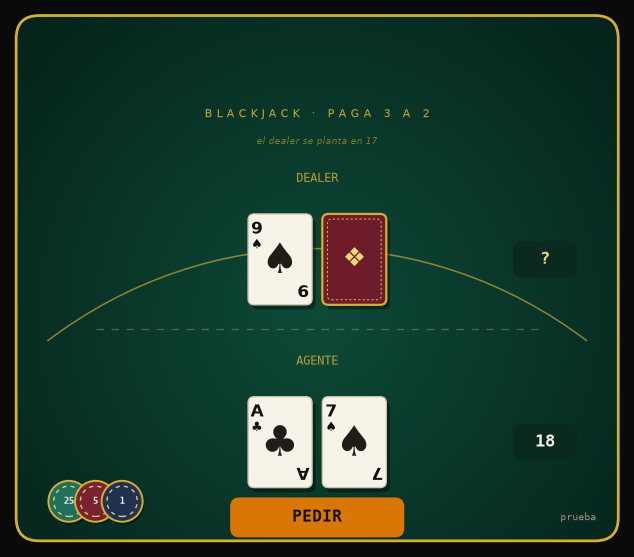

In [17]:
def render_mesa(ax, W, H, mano_jugador, mano_dealer, carta_oculta=True,
                suma_jugador=None, suma_dealer=None, decision=None, resultado=None, nota=None):
    """mano_* = lista de (etiqueta, palo); decision ∈ {'PEDIR', 'PLANTARSE', None}."""
    ax.clear(); ax.set_xlim(0, W); ax.set_ylim(0, H); ax.set_aspect("equal"); ax.axis("off")
    fondo_mesa(ax, W, H)
    paso = 1.45

    ax.text(W / 2, H * 0.685, "DEALER", ha="center", va="center", color=PAL["oro"],
            fontsize=8.5, family=MONO, alpha=0.85, zorder=3)
    x0 = W / 2 - (len(mano_dealer) - 1) * paso / 2
    for i, (et, pa) in enumerate(mano_dealer):
        dibujar_carta(ax, x0 + i * paso, H * 0.535, et, pa, oculta=(carta_oculta and i == 1), z=5 + i)
    _badge(ax, W - 1.55, H * 0.535, "?" if carta_oculta else f"{suma_dealer}",
           "#0A2A20", PAL["oro_claro"], fs=12, ancho=1.25, alto=0.72)

    ax.plot([W * 0.14, W * 0.86], [H * 0.405, H * 0.405], color=PAL["oro"], lw=0.9,
            ls=(0, (6, 6)), alpha=0.4, zorder=2)

    ax.text(W / 2, H * 0.345, "AGENTE", ha="center", va="center", color=PAL["oro"],
            fontsize=8.5, family=MONO, alpha=0.85, zorder=3)
    x0 = W / 2 - (len(mano_jugador) - 1) * paso / 2
    for i, (et, pa) in enumerate(mano_jugador):
        dibujar_carta(ax, x0 + i * paso, H * 0.195, et, pa, z=5 + i)
    if suma_jugador is not None:
        _badge(ax, W - 1.55, H * 0.195, f"{suma_jugador}", "#0A2A20",
               PAL["carta"] if suma_jugador <= 21 else PAL["rojo"], fs=12, ancho=1.25, alto=0.72)

    for i, (txt, col) in enumerate([("25", "#1F6F5C"), ("5", "#7A2230"), ("1", "#20324F")]):
        dibujar_ficha(ax, 1.15 + i * 0.52, H * 0.085, txt, col, r=0.40, z=6 + i)

    if decision:
        col = PAL["pedir"] if decision == "PEDIR" else PAL["plantarse"]
        _badge(ax, W / 2, H * 0.055, decision, col,
               PAL["tinta"] if decision == "PEDIR" else PAL["carta"], fs=11.5, ancho=3.4, alto=0.78)
    if nota:
        ax.text(W - 0.55, H * 0.055, nota, ha="right", va="center", color=PAL["texto2"],
                fontsize=7.5, family=MONO, zorder=9)
    if resultado:
        texto, color = resultado
        ax.add_patch(FancyBboxPatch((W * 0.18, H * 0.015), W * 0.64, H * 0.085,
                                    boxstyle="round,pad=0,rounding_size=0.22",
                                    fc="#000000", alpha=0.70, ec=color, lw=1.4, zorder=20))
        ax.text(W / 2, H * 0.0575, texto, ha="center", va="center", color=color,
                fontsize=15, fontweight="bold", family=MONO, zorder=21)


fig = figura(6.4, 5.6)
ax, W, H = eje(fig, [0.02, 0.02, 0.96, 0.96])
_rng = np.random.default_rng(3)
render_mesa(ax, W, H, [etiqueta_carta(1, _rng), etiqueta_carta(7, _rng)],
            [etiqueta_carta(9, _rng), etiqueta_carta(10, _rng)],
            suma_jugador=18, decision="PEDIR", nota="prueba")

## 6. La Q-table dibujada

Esta es la pieza central de la entrega. La **Q-table** es la memoria del agente: una casilla por
cada situación posible, y en cada casilla dos números, qué tan buena le ha resultado cada una de
las dos acciones. Dibujarla es dibujar lo que el agente cree.

La cuadrícula tiene las sumas del jugador en las filas (de 12 a 21) y la carta destapada del
dealer en las columnas (del as al 10). Se dibujan dos cuadrículas porque la situación es distinta
según si el as puede valer 11 o no, que es la tercera parte de la observación.

Cómo leer cada casilla:

- **El color y la letra** dicen la decisión: naranja con **P** es pedir, verde con **S** es
  plantarse. Siempre va la letra además del color, para que no dependa de distinguir colores.
- **Qué tan intenso** está el color dice qué tan convencido está el agente, o sea qué tan lejos
  están entre sí los dos números de la casilla. Un color pálido es una casilla donde casi le da
  igual.
- **Gris** significa que el agente nunca cayó en esa situación, así que no tiene opinión.
- **El recuadro dorado** marca las casillas donde el agente decidió distinto a la respuesta
  exacta de la celda 2.

La función `coincidencia_tabla` cuenta qué porcentaje de las 200 casillas coincide con la
respuesta exacta. Antes de entrenar da 55%, que es lo que acierta por pura casualidad una tabla
en ceros (en ceros el agente se planta siempre, y plantarse resulta ser lo correcto en poco más
de la mitad de las casillas).

In [18]:
SUMAS = list(range(21, 11, -1))                  # filas: 12 arriba, 21 abajo
DEALER = [1] + list(range(2, 11))                # columnas: A, 2..10
ETQ_DEALER = ["A"] + [str(c) for c in range(2, 11)]


def matrices(Q, N, usable):
    """Única fuente de lo que se dibuja: (decisión, confianza, visitas) en 10x10."""
    dec = np.zeros((len(SUMAS), 10), dtype=int)
    conf = np.zeros((len(SUMAS), 10))
    vis = np.zeros((len(SUMAS), 10))
    for i, suma in enumerate(SUMAS):
        for j, dc in enumerate(DEALER):
            q = Q[suma, dc, usable]
            dec[i, j] = int(np.argmax(q))
            conf[i, j] = abs(q[1] - q[0])
            vis[i, j] = N[suma, dc, usable].sum()
    return dec, conf, vis


def render_tabla(ax, dec, conf, vis, titulo, optima=None, resaltar=None):
    """Color = decisión, opacidad = confianza |ΔQ|, letra = decisión (nunca solo color).
    optima: marca en oro las casillas donde el agente difiere. resaltar: (fila, col)."""
    ax.clear()
    ax.set_xlim(-1.35, 10); ax.set_ylim(-0.45, 10.95); ax.axis("off")
    ax.text(-1.3, 10.55, titulo, ha="left", va="center", color=PAL["oro"],
            fontsize=9.5, family=MONO, fontweight="bold")
    for j, e in enumerate(ETQ_DEALER):
        ax.text(j + 0.5, 10.12, e, ha="center", va="center", color=PAL["texto2"],
                fontsize=8, family=MONO)
    ax.text(-1.3, 10.12, "dealer →", ha="left", va="center", color=PAL["texto2"],
            fontsize=6.6, family=MONO, style="italic")
    for i, s in enumerate(SUMAS):
        ax.text(-0.18, i + 0.5, str(s), ha="right", va="center", color=PAL["texto2"],
                fontsize=8, family=MONO)
    for i in range(len(SUMAS)):
        for j in range(10):
            if vis[i, j] < 1:
                ax.add_patch(Rectangle((j, i), 1, 1, fc=PAL["sin_visitar"], ec=PAL["lienzo"], lw=1.1))
                ax.text(j + 0.5, i + 0.5, "·", ha="center", va="center",
                        color="#55525A", fontsize=10, family=MONO)
                continue
            pedir = dec[i, j] == 1
            a = 0.40 + 0.60 * float(np.clip(conf[i, j] / 0.45, 0, 1))
            ax.add_patch(Rectangle((j, i), 1, 1, fc=PAL["pedir"] if pedir else PAL["plantarse"],
                                   alpha=a, ec=PAL["lienzo"], lw=1.1))
            ax.text(j + 0.5, i + 0.5, "P" if pedir else "S", ha="center", va="center",
                    color=PAL["tinta"] if pedir else PAL["carta"],
                    fontsize=9, fontweight="bold", family=MONO)
            if optima is not None and dec[i, j] != optima[i, j]:
                ax.add_patch(Rectangle((j + 0.06, i + 0.06), 0.88, 0.88, fc="none",
                                       ec=PAL["oro"], lw=2.0, zorder=6))
    if resaltar is not None:
        i, j = resaltar
        ax.add_patch(Rectangle((j - 0.09, i - 0.09), 1.18, 1.18, fc="none",
                               ec="#FFFFFF", lw=2.6, zorder=8))
        ax.add_patch(Rectangle((j - 0.24, i - 0.24), 1.48, 1.48, fc="none",
                               ec="#FFFFFF", lw=1.0, alpha=0.45, zorder=8))


def leyenda(fig, x, y, fs=7.6):
    """Leyenda compartida en coordenadas de figura (si va dentro de la tabla deja huecos)."""
    items = [(PAL["pedir"], "P", PAL["tinta"], "pedir"),
             (PAL["plantarse"], "S", PAL["carta"], "se planta"),
             (PAL["sin_visitar"], "·", "#55525A", "nunca visitada"),
             (None, "", PAL["oro"], "difiere de la óptima")]
    cx = x
    for col, letra, ctxt, txt in items:
        fig.patches.append(Rectangle((cx, y), 0.0115, 0.0205, transform=fig.transFigure,
                                     fc="none" if col is None else col,
                                     ec=PAL["oro"] if col is None else PAL["lienzo"],
                                     lw=1.6 if col is None else 1.0, zorder=12))
        if letra:
            fig.text(cx + 0.0058, y + 0.0102, letra, ha="center", va="center", color=ctxt,
                     fontsize=fs - 0.6, fontweight="bold", family=MONO, zorder=13)
        fig.text(cx + 0.016, y + 0.0102, txt, ha="left", va="center",
                 color=PAL["oro"] if col is None else PAL["texto2"], fontsize=fs, family=MONO)
        cx += 0.021 + 0.0072 * len(txt)


def coincidencia_tabla(Q, sumas=range(12, 22)):
    """% de las 200 casillas dibujadas que coinciden con la óptima exacta."""
    ok = tot = 0
    for u in (0, 1):
        for s_ in sumas:
            for dc in range(1, 11):
                tot += 1
                ok += int(np.argmax(Q[s_, dc, u]) == OPTIMA[s_, dc, u])
    return 100 * ok / tot


OPT_HARD = np.array([[OPTIMA[s, c, 0] for c in DEALER] for s in SUMAS])
OPT_SOFT = np.array([[OPTIMA[s, c, 1] for c in DEALER] for s in SUMAS])
T_HARD, T_SOFT = "MANO DURA · el as vale 1", "MANO SUAVE · el as vale 11"
print("renderizador de la tabla listo · tabla vacía =", f"{coincidencia_tabla(np.zeros((32,11,2,2))):.1f}%")

renderizador de la tabla listo · tabla vacía = 55.0%


## 7. El entrenamiento

Un millón de manos, unos 43 segundos. El ciclo es siempre el mismo: mirar la situación, elegir
una acción, ver qué pasó y corregir el número de esa casilla.

Tres decisiones del entrenamiento que vale la pena explicar, porque dos se apartan de lo que
decía la lámina de clase:

**El paso de aprendizaje es α = 1/N(s,a), no un número fijo.** `N` cuenta cuántas veces se ha
visitado cada casilla, así que las primeras visitas mueven mucho el valor y las siguientes cada
vez menos. Eso hace que cada casilla termine en el promedio verdadero de lo que pasó. Con un paso
fijo de 0.1 la tabla se queda temblando para siempre y se estanca en 87.5% de aciertos; con el
paso decreciente llega a 97.5%.

**La exploración nunca baja de 0.05.** Hay situaciones muy raras, sobre todo las que llevan un as
aprovechable. Si el agente dejara de probar al azar demasiado pronto, esas casillas se quedarían
mal aprendidas.

**No hay descuento (γ = 1).** El descuento sirve para darle menos peso a lo que pasa lejos en el
futuro. Aquí una mano dura dos o tres decisiones y la recompensa llega al final, así que no hay
nada que descontar.

Durante el entrenamiento se guardan 41 **fotos** de la tabla, repartidas de forma logarítmica
(más seguido al principio, que es cuando más cambia). Esas fotos son las que después se animan
para el video.

In [19]:
EPISODIOS = 1_000_000
GAMMA = 1.0
EPS_INICIAL, EPS_MIN = 1.0, 0.05

CORTES = sorted(set([0] + [int(round(x)) for x in np.geomspace(500, EPISODIOS, 40)]))
env_tr = gym.make("Blackjack-v1")
env_tr.reset(seed=0)
env_tr.action_space.seed(0)
rng = np.random.default_rng(0)

Q = np.zeros((32, 11, 2, 2))
N = np.zeros((32, 11, 2, 2))
decay = EPS_MIN ** (1 / (0.8 * EPISODIOS))
epsilon = EPS_INICIAL
CKPT_EP, CKPT_Q, CKPT_N = [], [], []

t0 = time.time()
for ep in range(EPISODIOS):
    if ep in CORTES:
        CKPT_EP.append(ep); CKPT_Q.append(Q.copy()); CKPT_N.append(N.copy())
    s, _ = env_tr.reset()
    fin = False
    while not fin:
        if rng.random() < epsilon:
            a = int(env_tr.action_space.sample())          # explorar
        else:
            a = int(np.argmax(Q[s]))                       # explotar
        s2, r, term, trunc, _ = env_tr.step(a)
        N[s][a] += 1
        objetivo = r if term else r + GAMMA * np.max(Q[s2])
        Q[s][a] += (objetivo - Q[s][a]) / N[s][a]          # alpha = 1/N(s,a)
        s = s2
        fin = term or trunc
    epsilon = max(EPS_MIN, epsilon * decay)
    if (ep + 1) % 200_000 == 0:
        print(f"  episodio {ep+1:>9,} | coincidencia {coincidencia_tabla(Q):5.1f}% | epsilon {epsilon:.3f}")

CKPT_EP.append(EPISODIOS); CKPT_Q.append(Q.copy()); CKPT_N.append(N.copy())
CKPT_EP = np.array(CKPT_EP)
COIN = np.array([coincidencia_tabla(q) for q in CKPT_Q])
print("\nentrenamiento: %.1f s" % (time.time() - t0))
print("coincidencia con la óptima: %.1f%% (de %.1f%% al inicio)" % (COIN[-1], COIN[0]))

EV_AGENTE = evaluar(lambda s, rng: int(np.argmax(Q[s])))
print("EV del agente: %+.4f | gana %.1f%% | empata %.1f%%" % EV_AGENTE)
print("EV de la óptima exacta: %+.4f" % BASES["óptima exacta"][0])

  episodio   200,000 | coincidencia  96.5% | epsilon 0.473
  episodio   400,000 | coincidencia  97.0% | epsilon 0.224
  episodio   600,000 | coincidencia  97.0% | epsilon 0.106
  episodio   800,000 | coincidencia  97.5% | epsilon 0.050
  episodio 1,000,000 | coincidencia  97.5% | epsilon 0.050

entrenamiento: 43.9 s
coincidencia con la óptima: 97.5% (de 55.0% al inicio)
EV del agente: -0.0428 | gana 43.3% | empata 9.2%
EV de la óptima exacta: -0.0421


## 8. Lo que aprendió, al lado de la respuesta exacta

Las cuatro cuadrículas: a la izquierda lo que el agente cree después del millón de manos, a la
derecha la respuesta exacta. Arriba las manos sin as aprovechable, abajo las que sí lo tienen.

Si todo salió bien, los dos lados se ven casi idénticos, y las pocas casillas con recuadro dorado
son las que el agente todavía no clava.

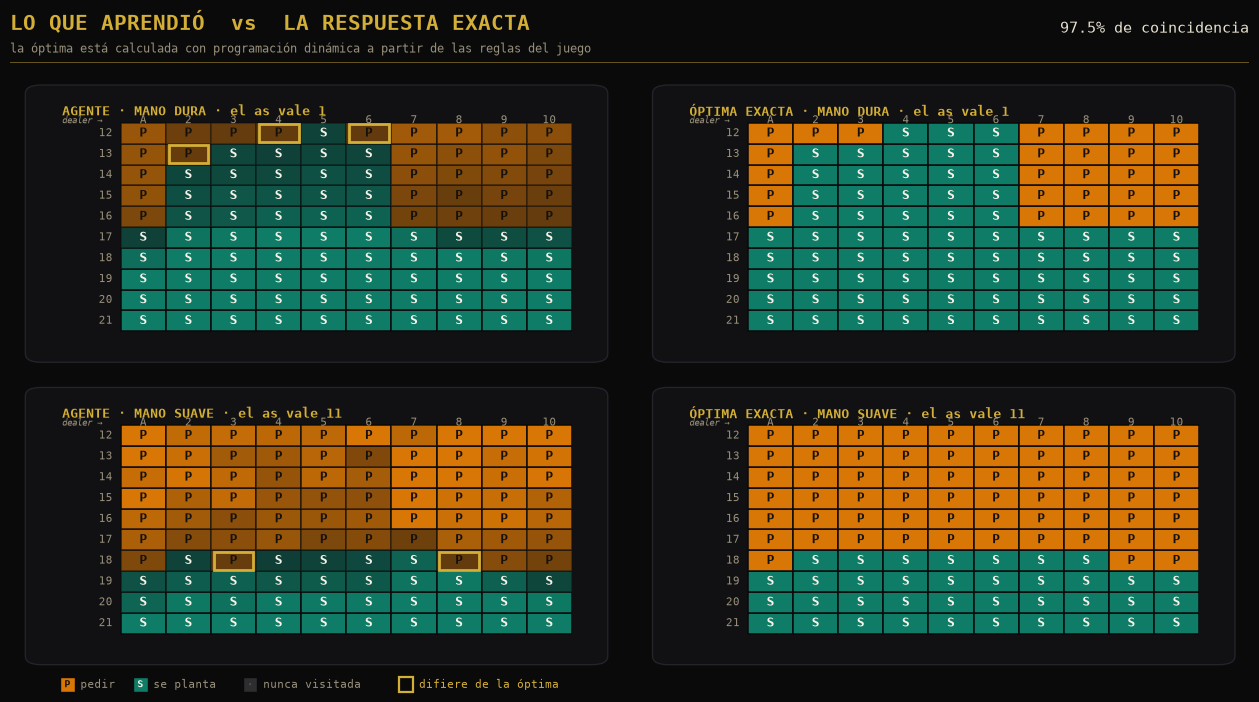

In [20]:
SALIDA = "video_blackjack"
os.makedirs(SALIDA, exist_ok=True)

fig = figura()
encabezado(fig, "LO QUE APRENDIÓ  vs  LA RESPUESTA EXACTA",
           "la óptima está calculada con programación dinámica a partir de las reglas del juego",
           f"{COIN[-1]:.1f}% de coincidencia")
for fila, (u, titulo, opt) in enumerate([(0, T_HARD, OPT_HARD), (1, T_SOFT, OPT_SOFT)]):
    dec, conf, vis = matrices(Q, N, u)
    y = 0.52 - fila * 0.42
    panel(fig, [0.028, y - 0.03, 0.455, 0.385]); panel(fig, [0.518, y - 0.03, 0.455, 0.385])
    a = fig.add_axes([0.055, y, 0.40, 0.33])
    render_tabla(a, dec, conf, vis, "AGENTE · " + titulo, opt)
    b = fig.add_axes([0.545, y, 0.40, 0.33])
    render_tabla(b, opt, np.full_like(conf, 0.45), np.ones_like(vis), "ÓPTIMA EXACTA · " + titulo)
leyenda(fig, 0.055, 0.032)
fig.savefig(f"{SALIDA}/fig_tabla_final.png", facecolor=PAL["lienzo"], dpi=140)

## 9. Cómo fue aprendiendo

Dos gráficas. La de la izquierda es el porcentaje de casillas que coinciden con la respuesta
exacta, episodio por episodio, en escala logarítmica para que se alcance a ver tanto el arranque
como el final. La de la derecha compara el EV del agente contra las cuatro políticas de la celda
3: cuanto más corta la barra, mejor se juega.

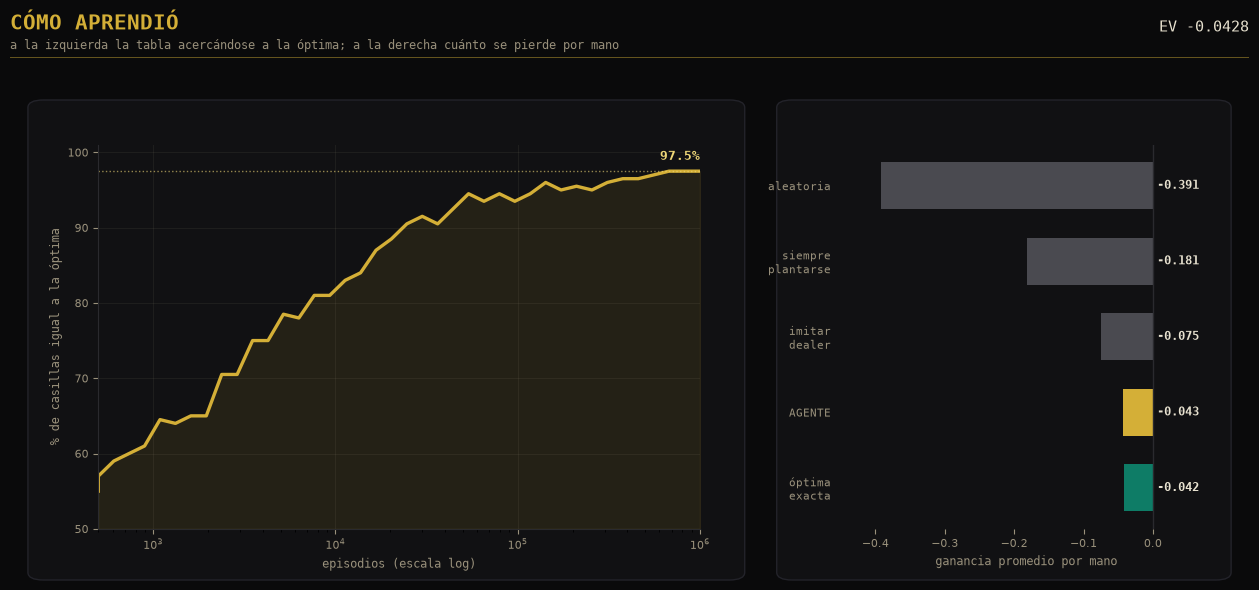

In [21]:
fig = figura(12.8, 6.4)
encabezado(fig, "CÓMO APRENDIÓ",
           "a la izquierda la tabla acercándose a la óptima; a la derecha cuánto se pierde por mano",
           f"EV {EV_AGENTE[0]:+.4f}")
panel(fig, [0.03, 0.09, 0.56, 0.75])
ax = fig.add_axes([0.085, 0.17, 0.47, 0.60], facecolor="none")
x = np.maximum(CKPT_EP, 500)
ax.plot(x, COIN, color=PAL["oro"], lw=2.4)
ax.fill_between(x, 50, COIN, color=PAL["oro"], alpha=0.10)
ax.set_xscale("log"); ax.set_xlim(500, CKPT_EP[-1]); ax.set_ylim(50, 101)
ax.tick_params(colors=PAL["texto2"], labelsize=8)
for k, sp in ax.spines.items():
    sp.set_visible(k in ("bottom", "left")); sp.set_color("#2A2A2E")
ax.grid(alpha=0.10, color=PAL["texto2"])
ax.set_xlabel("episodios (escala log)", color=PAL["texto2"], fontsize=8.5, family=MONO)
ax.set_ylabel("% de casillas igual a la óptima", color=PAL["texto2"], fontsize=8.5, family=MONO)
ax.axhline(COIN[-1], color=PAL["oro_claro"], ls=":", lw=1, alpha=0.6)
ax.text(CKPT_EP[-1], COIN[-1] + 1.5, f"{COIN[-1]:.1f}%", color=PAL["oro_claro"],
        fontsize=9.5, family=MONO, ha="right", fontweight="bold")

panel(fig, [0.615, 0.09, 0.355, 0.75])
bx = fig.add_axes([0.665, 0.17, 0.29, 0.60], facecolor="none")
etiquetas = ["aleatoria", "siempre\nplantarse", "imitar\ndealer", "AGENTE", "óptima\nexacta"]
valores = [BASES["aleatoria"][0], BASES["siempre plantarse"][0], BASES["imitar dealer"][0],
           EV_AGENTE[0], BASES["óptima exacta"][0]]
colores = ["#4A4A50", "#4A4A50", "#4A4A50", PAL["oro"], PAL["plantarse"]]
barras = bx.barh(range(5), valores, color=colores, height=0.62)
bx.set_yticks(range(5)); bx.set_yticklabels(etiquetas, color=PAL["texto2"], fontsize=8, family=MONO)
bx.invert_yaxis(); bx.set_xlim(-0.45, 0.085)
bx.tick_params(colors=PAL["texto2"], labelsize=8, left=False)
for sp in bx.spines.values():
    sp.set_visible(False)
bx.axvline(0, color="#2A2A2E", lw=1)
bx.set_xlabel("ganancia promedio por mano", color=PAL["texto2"], fontsize=8.5, family=MONO)
for b, v in zip(barras, valores):
    bx.text(0.006, b.get_y() + b.get_height() / 2, f"{v:+.3f}", ha="left", va="center",
            color=PAL["texto"], fontsize=8.5, family=MONO, fontweight="bold")
fig.savefig(f"{SALIDA}/fig_curva.png", facecolor=PAL["lienzo"], dpi=140)

## 10. Video: la Q-table naciendo

Este es el clip principal del entregable. Recorre las 41 fotos de la tabla, de la primera a la
última, con la curva de aprendizaje abajo marcando en qué momento vamos.

Empieza con las 200 casillas en gris, porque el agente todavía no ha visto nada. Después se llena
de naranja y verde revueltos, con muchos recuadros dorados marcando los errores. Y hacia el final
se acomoda solo en el patrón que cualquiera reconoce de la estrategia básica. Ese patrón nunca se
programó: aparece de jugar y contar.

In [22]:
import imageio


def curva_mini(fig, rect, idx):
    panel(fig, [rect[0] - 0.03, rect[1] - 0.06, rect[2] + 0.055, rect[3] + 0.095])
    ax = fig.add_axes(rect, facecolor="none")
    x = np.maximum(CKPT_EP, 500)
    ax.plot(x, COIN, color=PAL["oro"], lw=2.2, solid_capstyle="round")
    ax.fill_between(x, 50, COIN, color=PAL["oro"], alpha=0.10)
    ax.scatter([x[idx]], [COIN[idx]], s=70, color="#FFFFFF", zorder=5, ec=PAL["oro"], lw=1.5)
    ax.set_xscale("log"); ax.set_xlim(500, CKPT_EP[-1]); ax.set_ylim(50, 101)
    ax.set_yticks([60, 80, 100]); ax.tick_params(colors=PAL["texto2"], labelsize=7.5)
    for k, sp in ax.spines.items():
        sp.set_visible(k == "bottom"); sp.set_color("#2A2A2E")
    ax.grid(alpha=0.10, color=PAL["texto2"])
    ax.set_ylabel("% igual a la\nestrategia óptima", color=PAL["texto2"], fontsize=7.5, family=MONO)
    ax.annotate(f"{COIN[idx]:.0f}%", (x[idx], COIN[idx]), textcoords="offset points",
                xytext=(-16, 9), color="#FFFFFF", fontsize=9.5, family=MONO,
                fontweight="bold", ha="center", annotation_clip=False)


def clip_tabla(fps=10, repite=4, cola=30):
    frames = []
    for idx in range(len(CKPT_EP)):
        fig = figura()
        encabezado(fig, "LA Q-TABLE APRENDIENDO",
                   "cada casilla es una situación posible · el color es lo que el agente decide ahí",
                   f"episodio {CKPT_EP[idx]:,}")
        panel(fig, [0.028, 0.285, 0.455, 0.60]); panel(fig, [0.518, 0.285, 0.455, 0.60])
        d1, c1, v1 = matrices(CKPT_Q[idx], CKPT_N[idx], 0)
        d2, c2, v2 = matrices(CKPT_Q[idx], CKPT_N[idx], 1)
        a1 = fig.add_axes([0.055, 0.315, 0.40, 0.53]); render_tabla(a1, d1, c1, v1, T_HARD, OPT_HARD)
        a2 = fig.add_axes([0.545, 0.315, 0.40, 0.53]); render_tabla(a2, d2, c2, v2, T_SOFT, OPT_SOFT)
        leyenda(fig, 0.055, 0.262)
        curva_mini(fig, [0.075, 0.105, 0.89, 0.115], idx)
        frames.extend([a_frame(fig)] * repite)
        plt.close(fig)
    frames.extend([frames[-1]] * cola)
    imageio.mimsave(f"{SALIDA}/clip_tabla.mp4", frames, fps=fps, macro_block_size=1)
    imageio.mimsave(f"{SALIDA}/clip_tabla.gif", frames[::3], fps=fps / 3, loop=0)
    print("clip_tabla: %.1f s de video · %d frames de %dx%d"
          % (len(frames) / fps, len(frames), frames[0].shape[1], frames[0].shape[0]))


t0 = time.time(); clip_tabla(); print("generado en %.1f s" % (time.time() - t0))

clip_tabla: 19.4 s de video · 194 frames de 1280x720
generado en 13.5 s


## 11. Video: el agente jugando

Tres momentos del entrenamiento —recién nacido, a los diez mil episodios y al millón— jugando con
la misma semilla, para que las cartas sean parecidas y lo que se note sea el cambio de criterio y
no la suerte.

A la izquierda la mesa, a la derecha su tabla, y la casilla que está consultando en ese momento
se resalta en blanco. Abajo se leen los dos números que está comparando para decidir. En el
episodio 0 la tabla está vacía y el agente se planta siempre, porque con todo en ceros la
comparación siempre termina empatada y gana la primera opción.

In [23]:
def suma_mano(cartas):
    """Misma regla que gymnasium: el as vale 11 si no pasa de 21."""
    total = sum(cartas)
    return total + 10 if (1 in cartas and total + 10 <= 21) else total


def jugar_mano(env, Q, rng_palos):
    """Juega una mano con la política greedy y devuelve las escenas para dibujar."""
    s, _ = env.reset()
    u = env.unwrapped
    cartas_j = [etiqueta_carta(v, rng_palos) for v in u.player]
    cartas_d = [etiqueta_carta(v, rng_palos) for v in u.dealer]
    escenas, fin, r = [], False, 0.0
    while not fin:
        a = int(np.argmax(Q[s]))
        q = Q[s]
        escenas.append(dict(j=list(cartas_j), d=list(cartas_d), oculta=True, suma=s[0], suma_d=None,
                            decision="PEDIR" if a else "PLANTARSE",
                            celda=(s[0], s[1], s[2]), q=(q[1], q[0]), resultado=None))
        s2, r, term, trunc, _ = env.step(a)
        if a == 1 and len(u.player) > len(cartas_j):
            cartas_j += [etiqueta_carta(v, rng_palos) for v in list(u.player)[len(cartas_j):]]
        s = s2
        fin = term or trunc
    if len(u.dealer) > len(cartas_d):
        cartas_d += [etiqueta_carta(v, rng_palos) for v in list(u.dealer)[len(cartas_d):]]
    texto, color = {1.0: ("GANA LA MANO", PAL["oro_claro"]),
                    0.0: ("EMPATE", PAL["texto"]),
                    -1.0: ("PIERDE LA MANO", PAL["rojo"])}[float(r)]
    escenas.append(dict(j=list(cartas_j), d=list(cartas_d), oculta=False,
                        suma=suma_mano(u.player), suma_d=suma_mano(u.dealer),
                        decision=None, celda=None, q=None, resultado=(texto, color)))
    return escenas


def frame_jugando(escena, idx_ck, etiqueta_etapa, n_mano, total_manos):
    fig = figura()
    encabezado(fig, "EL AGENTE JUGANDO", etiqueta_etapa, f"episodio {CKPT_EP[idx_ck]:,}")
    panel(fig, [0.502, 0.03, 0.486, 0.866])
    ax, W, H = eje(fig, [0.014, 0.06, 0.47, 0.83])
    render_mesa(ax, W, H, escena["j"], escena["d"], carta_oculta=escena["oculta"],
                suma_jugador=escena["suma"], suma_dealer=escena["suma_d"],
                decision=escena["decision"], resultado=escena["resultado"],
                nota=f"mano {n_mano}/{total_manos}")
    resaltar = {0: None, 1: None}
    sub = "la tabla todavía no dice nada"
    if escena["celda"] is not None:
        suma, dc, usable = escena["celda"]
        if suma in SUMAS:
            resaltar[usable] = (SUMAS.index(suma), DEALER.index(dc))
        qp, qs = escena["q"]
        sub = (f"consulta  suma {suma} · dealer {'A' if dc == 1 else dc} · "
               f"{'as vale 11' if usable else 'as vale 1'}      "
               f"Q(pedir) {qp:+.3f}   Q(plantarse) {qs:+.3f}")
    for u, titulo, opt, y in [(0, T_HARD, OPT_HARD, 0.495), (1, T_SOFT, OPT_SOFT, 0.115)]:
        dec, conf, vis = matrices(CKPT_Q[idx_ck], CKPT_N[idx_ck], u)
        a = fig.add_axes([0.545, y, 0.40, 0.355])
        render_tabla(a, dec, conf, vis, titulo, opt, resaltar=resaltar[u])
    leyenda(fig, 0.545, 0.062)
    fig.text(0.745, 0.038, sub, ha="center", va="center", color=PAL["texto2"],
             fontsize=8, family=MONO)
    f = a_frame(fig)
    plt.close(fig)
    return f


def clip_jugando(etapas, manos=4, fps=12, semilla=11):
    frames = []
    for idx_ck, etiqueta in etapas:
        env_j = gym.make("Blackjack-v1")
        env_j.reset(seed=semilla)
        rng_palos = np.random.default_rng(semilla)
        for n in range(1, manos + 1):
            for e in jugar_mano(env_j, CKPT_Q[idx_ck], rng_palos):
                f = frame_jugando(e, idx_ck, etiqueta, n, manos)
                frames.extend([f] * (11 if e["resultado"] else 8))
    imageio.mimsave(f"{SALIDA}/clip_jugando.mp4", frames, fps=fps, macro_block_size=1)
    imageio.mimsave(f"{SALIDA}/clip_jugando.gif", frames[::4], fps=fps / 4, loop=0)
    print("clip_jugando: %.1f s de video · %d frames" % (len(frames) / fps, len(frames)))


idx_medio = int(np.argmin(np.abs(CKPT_EP - 10_000)))
ETAPAS = [(0, "episodio 0 · la tabla está vacía, decide a ciegas"),
          (idx_medio, "10 mil episodios · ya tiene opinión, todavía se equivoca"),
          (len(CKPT_EP) - 1, "1 millón de episodios · juega la estrategia óptima")]
t0 = time.time(); clip_jugando(ETAPAS); print("generado en %.1f s" % (time.time() - t0))

clip_jugando: 24.3 s de video · 292 frames
generado en 13.0 s


## 12. Verificación

Tres comprobaciones para que nadie tenga que creernos de palabra.

La primera revisa que lo que se dibuja en la cuadrícula sea exactamente lo que dice la Q-table, y
no una versión embellecida. La segunda juega cinco mil manos y comprueba que la acción que el
agente *realmente toma* es la misma letra que está pintada en la casilla, o sea que el panel y el
jugador son la misma cosa. La tercera lista las casillas donde el agente difiere de la respuesta
exacta y, usando `BRECHA`, dice cuánto cuesta cada diferencia.

In [24]:
for u in (0, 1):
    dec, conf, vis = matrices(Q, N, u)
    for i, s in enumerate(SUMAS):
        for j, dc in enumerate(DEALER):
            assert dec[i, j] == int(np.argmax(Q[s, dc, u]))
            assert vis[i, j] == N[s, dc, u].sum()
print("1) las 200 casillas dibujadas son exactamente argmax(Q)")

env_v = gym.make("Blackjack-v1"); env_v.reset(seed=99)
decs = {u: matrices(Q, N, u)[0] for u in (0, 1)}
revisadas = 0
for _ in range(5000):
    s, _ = env_v.reset()
    fin = False
    while not fin:
        a = int(np.argmax(Q[s]))
        if s[0] in SUMAS:
            assert decs[s[2]][SUMAS.index(s[0]), DEALER.index(s[1])] == a
            revisadas += 1
        s, r, term, trunc, _ = env_v.step(a)
        fin = term or trunc
print(f"2) {revisadas:,} decisiones jugadas coinciden con la letra dibujada")

desacuerdos = [(s, dc, u, BRECHA[s, dc, u]) for u in (0, 1) for s in range(12, 22)
               for dc in range(1, 11) if np.argmax(Q[s, dc, u]) != OPTIMA[s, dc, u]]
print(f"3) {len(desacuerdos)} casillas distintas de la óptima, de 200 ({COIN[-1]:.1f}% iguales)")
for s, dc, u, b in sorted(desacuerdos, key=lambda m: -m[3]):
    print(f"     suma {s:>2} vs dealer {'A' if dc == 1 else dc:>2} "
          f"({'as vale 11' if u else 'as vale  1'}) · cuesta {b:.4f} por mano")
print(f"4) EV del agente {EV_AGENTE[0]:+.4f} contra {BASES['óptima exacta'][0]:+.4f} de la óptima")
print("\narchivos en", SALIDA + "/:")
for f in sorted(os.listdir(SALIDA)):
    print(f"   {f:24s} {os.path.getsize(os.path.join(SALIDA, f))/1e6:6.2f} MB")

1) las 200 casillas dibujadas son exactamente argmax(Q)
2) 6,650 decisiones jugadas coinciden con la letra dibujada
3) 5 casillas distintas de la óptima, de 200 (97.5% iguales)
     suma 18 vs dealer  8 (as vale 11) · cuesta 0.0663 por mano
     suma 18 vs dealer  3 (as vale 11) · cuesta 0.0581 por mano
     suma 12 vs dealer  6 (as vale  1) · cuesta 0.0168 por mano
     suma 13 vs dealer  2 (as vale  1) · cuesta 0.0150 por mano
     suma 12 vs dealer  4 (as vale  1) · cuesta 0.0025 por mano
4) EV del agente -0.0428 contra -0.0421 de la óptima

archivos en video_blackjack/:
   clip_jugando.gif           2.11 MB
   clip_jugando.mp4           0.41 MB
   clip_tabla.gif             1.96 MB
   clip_tabla.mp4             0.43 MB
   fig_curva.png              0.08 MB
   fig_tabla_final.png        0.20 MB
